In [18]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             accuracy_score, confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
ROOT = Path("..") if Path.cwd().name == "notebooks" else Path(".")
IMG, SAMPLES = ROOT / "images", ROOT / "data" / "samples"
IMG.mkdir(exist_ok=True)

def table_image(df, path, n=6, decimals=2):
    show = df.head(n).round(decimals).astype(str)
    fig, ax = plt.subplots(figsize=(max(8, 1.3 * show.shape[1]), 0.5 * (n + 1.5)))
    ax.axis("off")
    t = ax.table(cellText=show.values, colLabels=show.columns, loc="center", cellLoc="center")
    t.auto_set_font_size(False); t.set_fontsize(9); t.scale(1, 1.5)
    t.auto_set_column_width(list(range(show.shape[1])))
    for (r, c), cell in t.get_celld().items():
        cell.set_edgecolor("#cccccc")
        if r == 0:
            cell.set_facecolor("#1f3a5f"); cell.set_text_props(color="white", weight="bold")
    fig.savefig(path, dpi=200, bbox_inches="tight"); plt.close(fig)
    display(Image(str(path)))

In [19]:
sample = pd.read_csv(SAMPLES / "supervised_sample_labeled.csv")
sample = pd.concat([sample, pd.get_dummies(sample.position, prefix="pos", dtype=int)], axis=1)
sample["is_high"] = (sample.value_tier == "High").astype(int)

train, test = train_test_split(sample, test_size=0.2, stratify=sample.value_tier, random_state=42)
assert set(train.index).isdisjoint(test.index)

part3_train = pd.read_csv(SAMPLES / "dt_train.csv")
print("train:", len(train), " test:", len(test), " overlap:", len(set(train.index) & set(test.index)))
print("same split as Part 3:", (train.name.values == part3_train.name.values).all())
print("share of High players  train:", round(train.is_high.mean(), 3), " test:", round(test.is_high.mean(), 3))

train: 4000  test: 1000  overlap: 0
same split as Part 3: True
share of High players  train: 0.333  test: 0.334


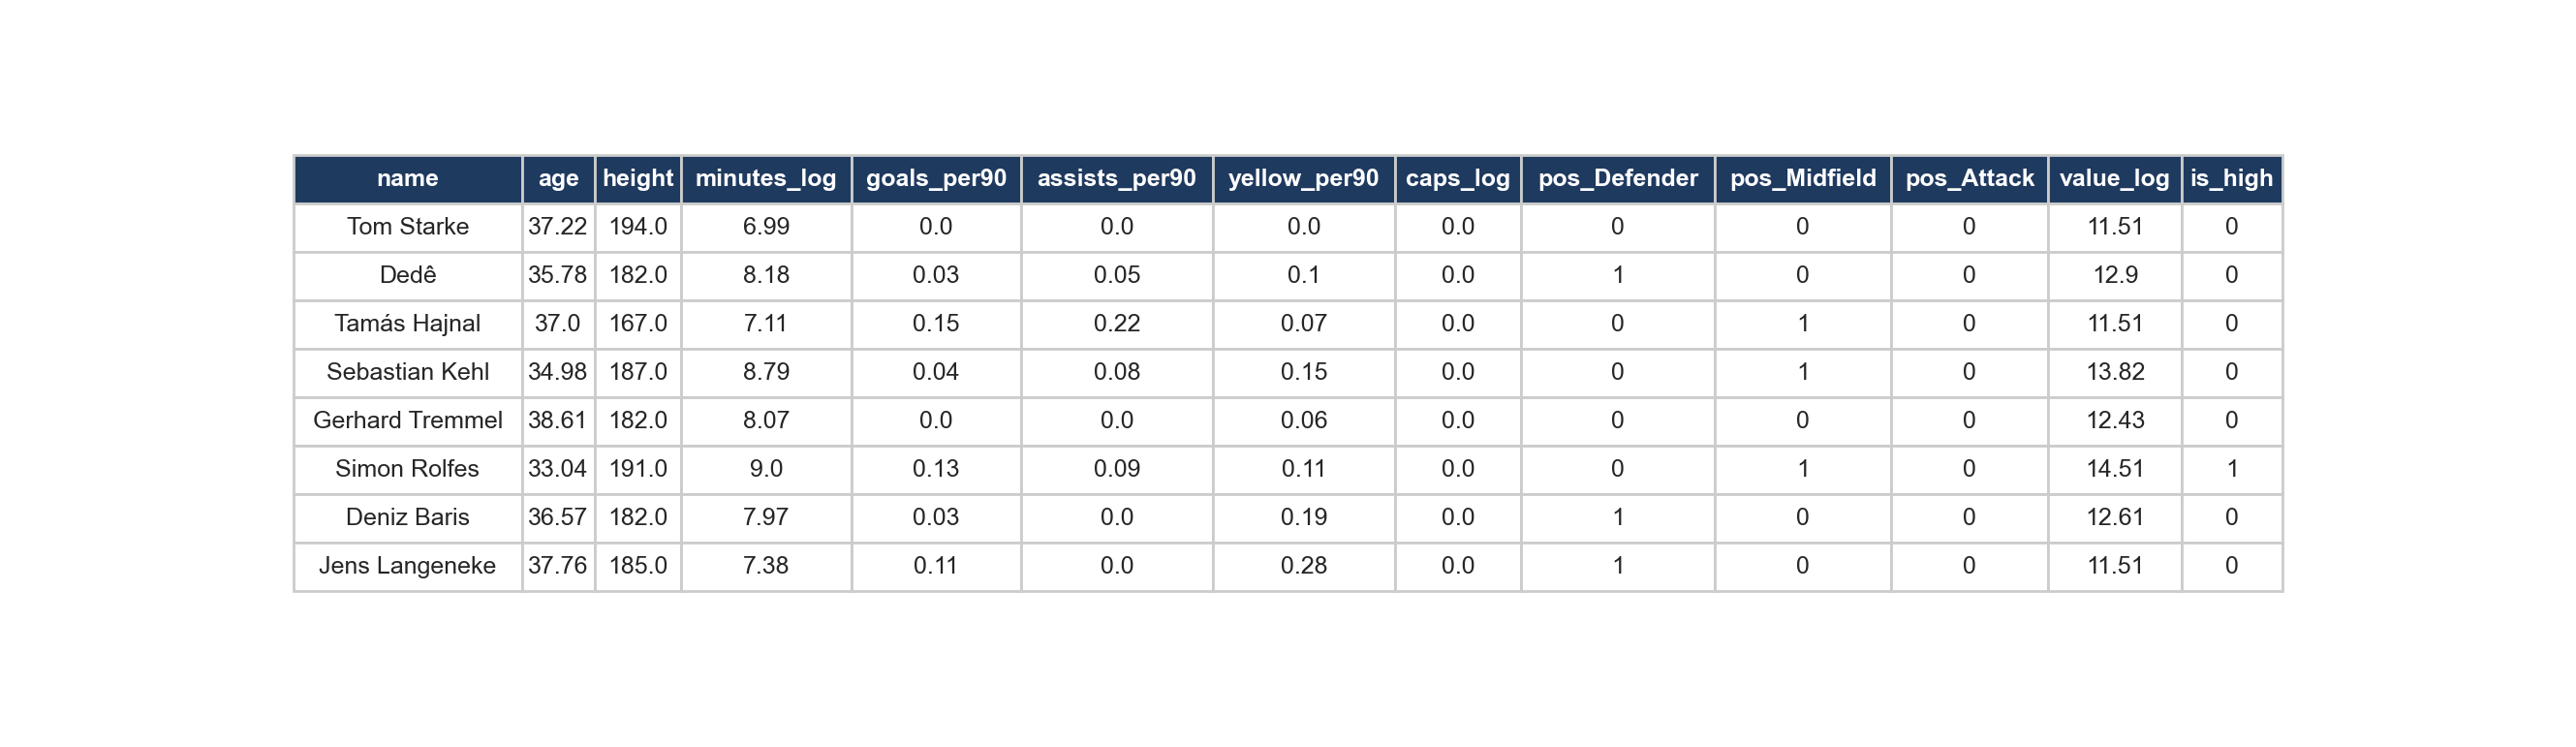

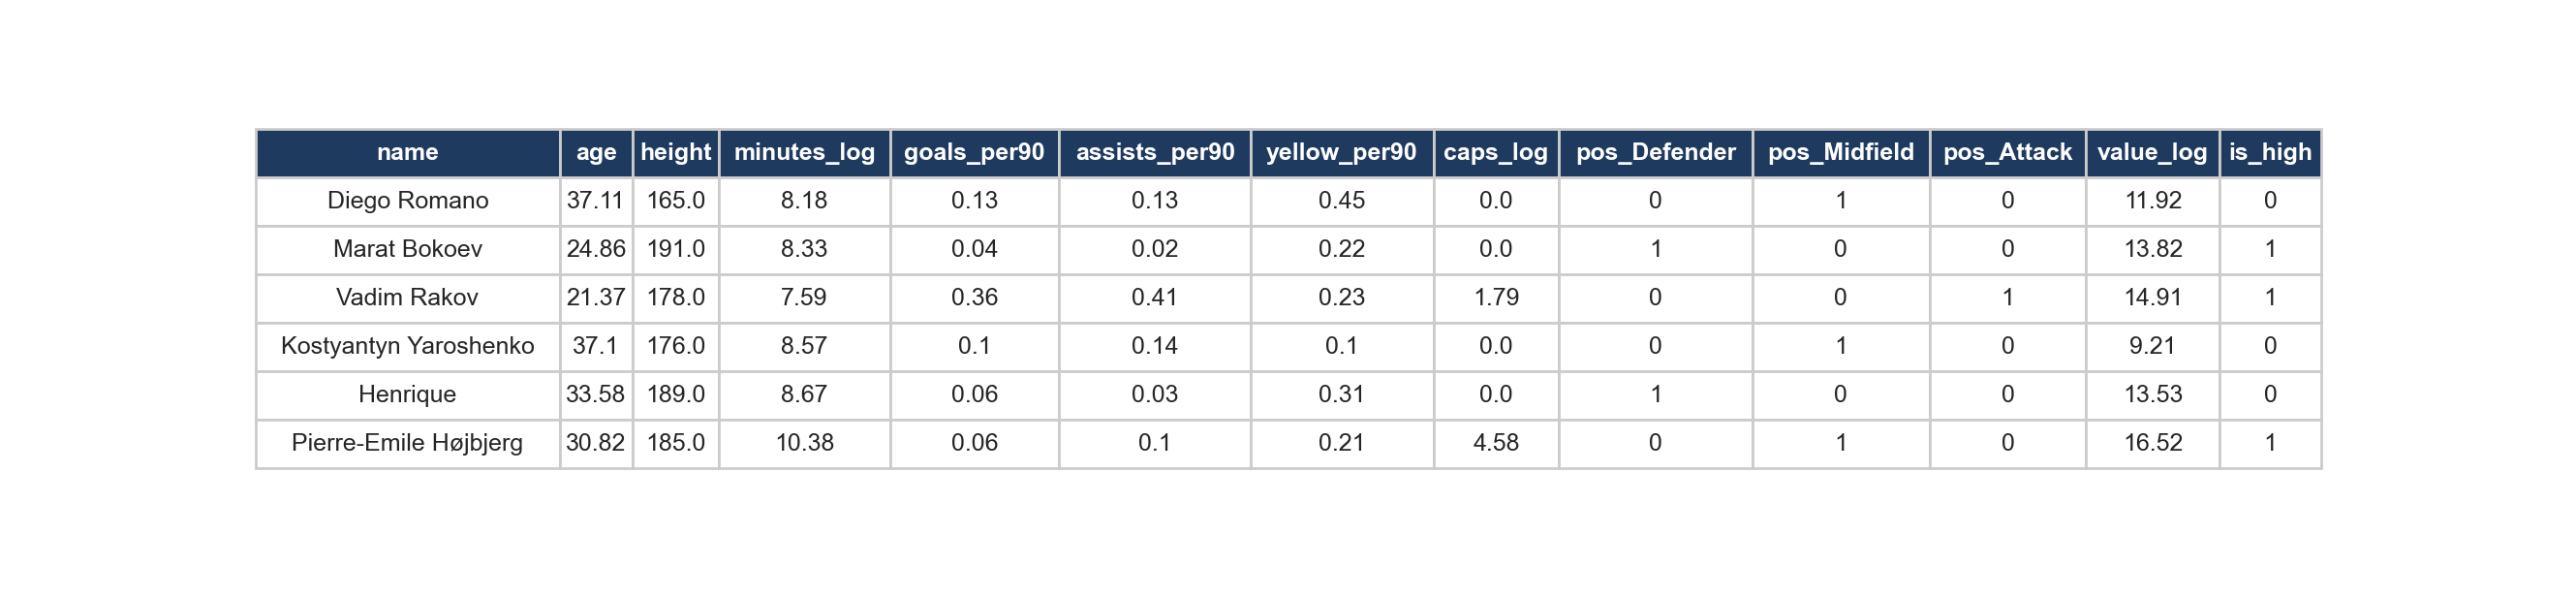

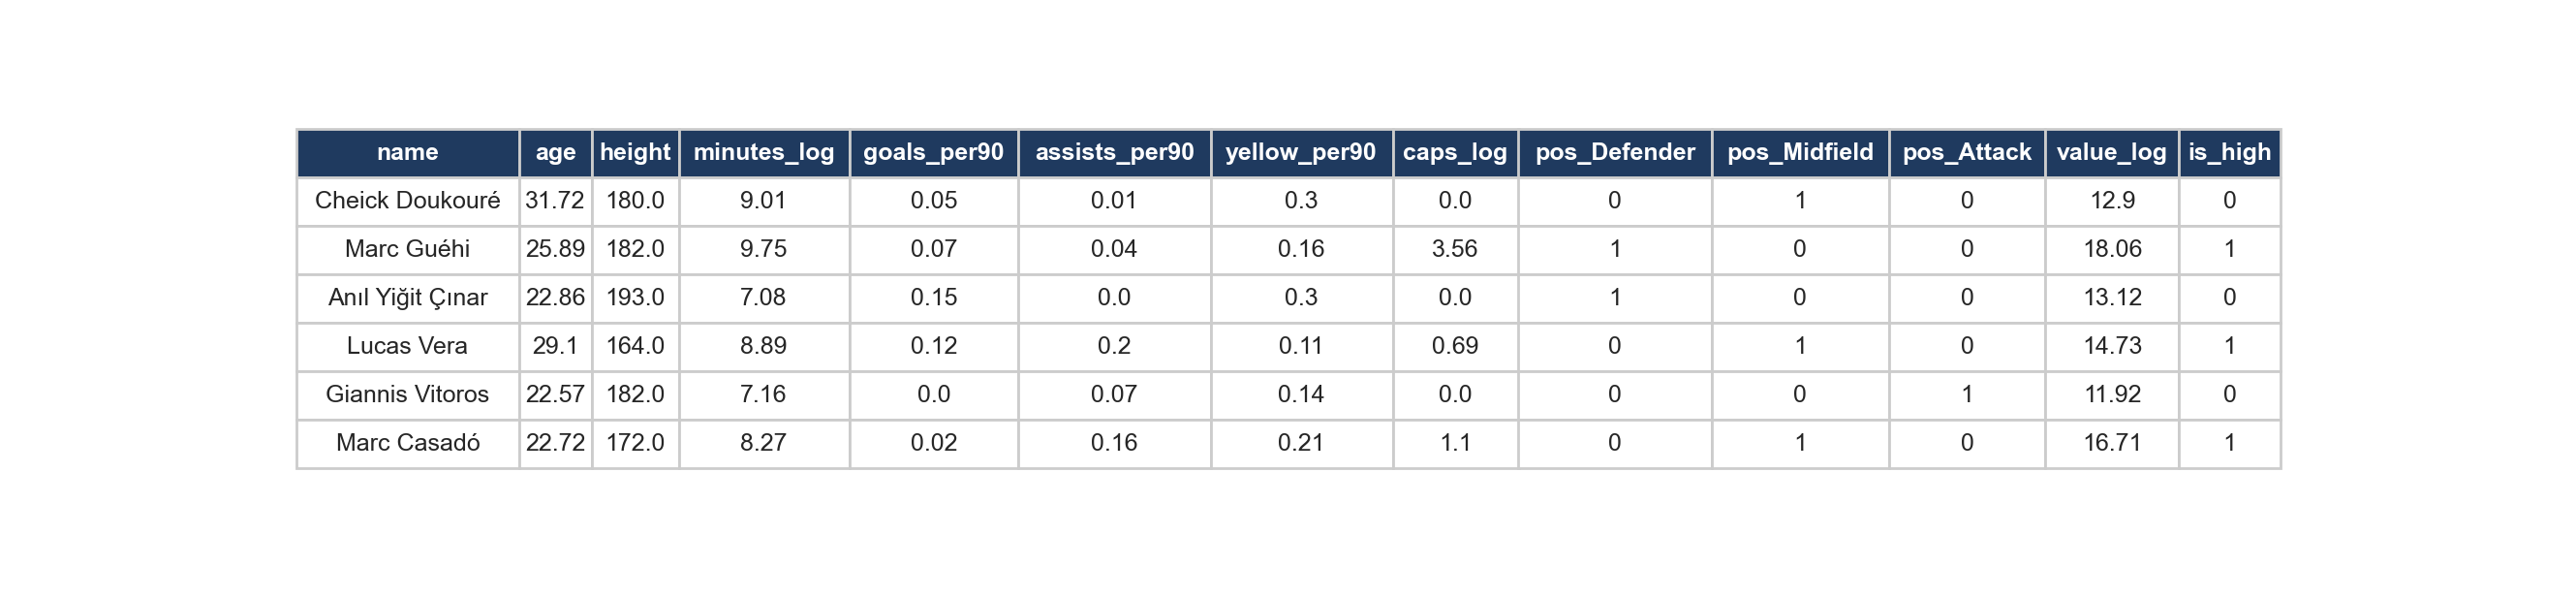

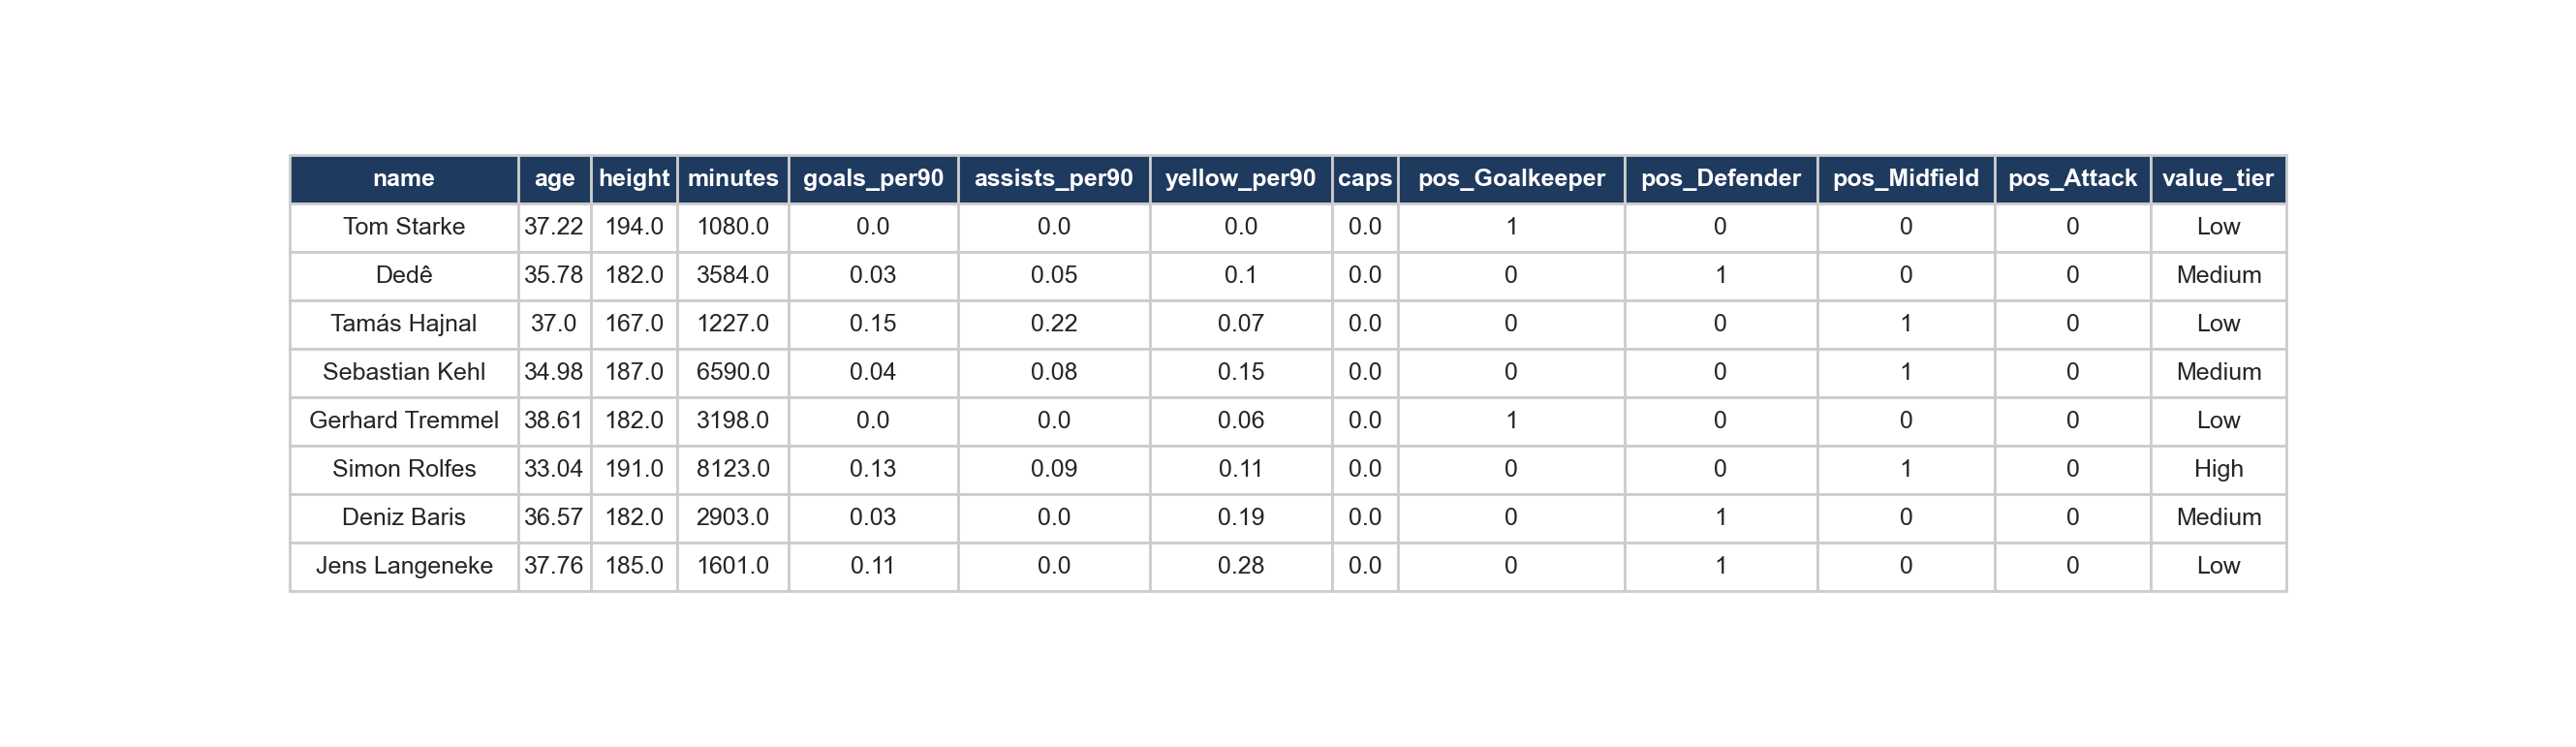

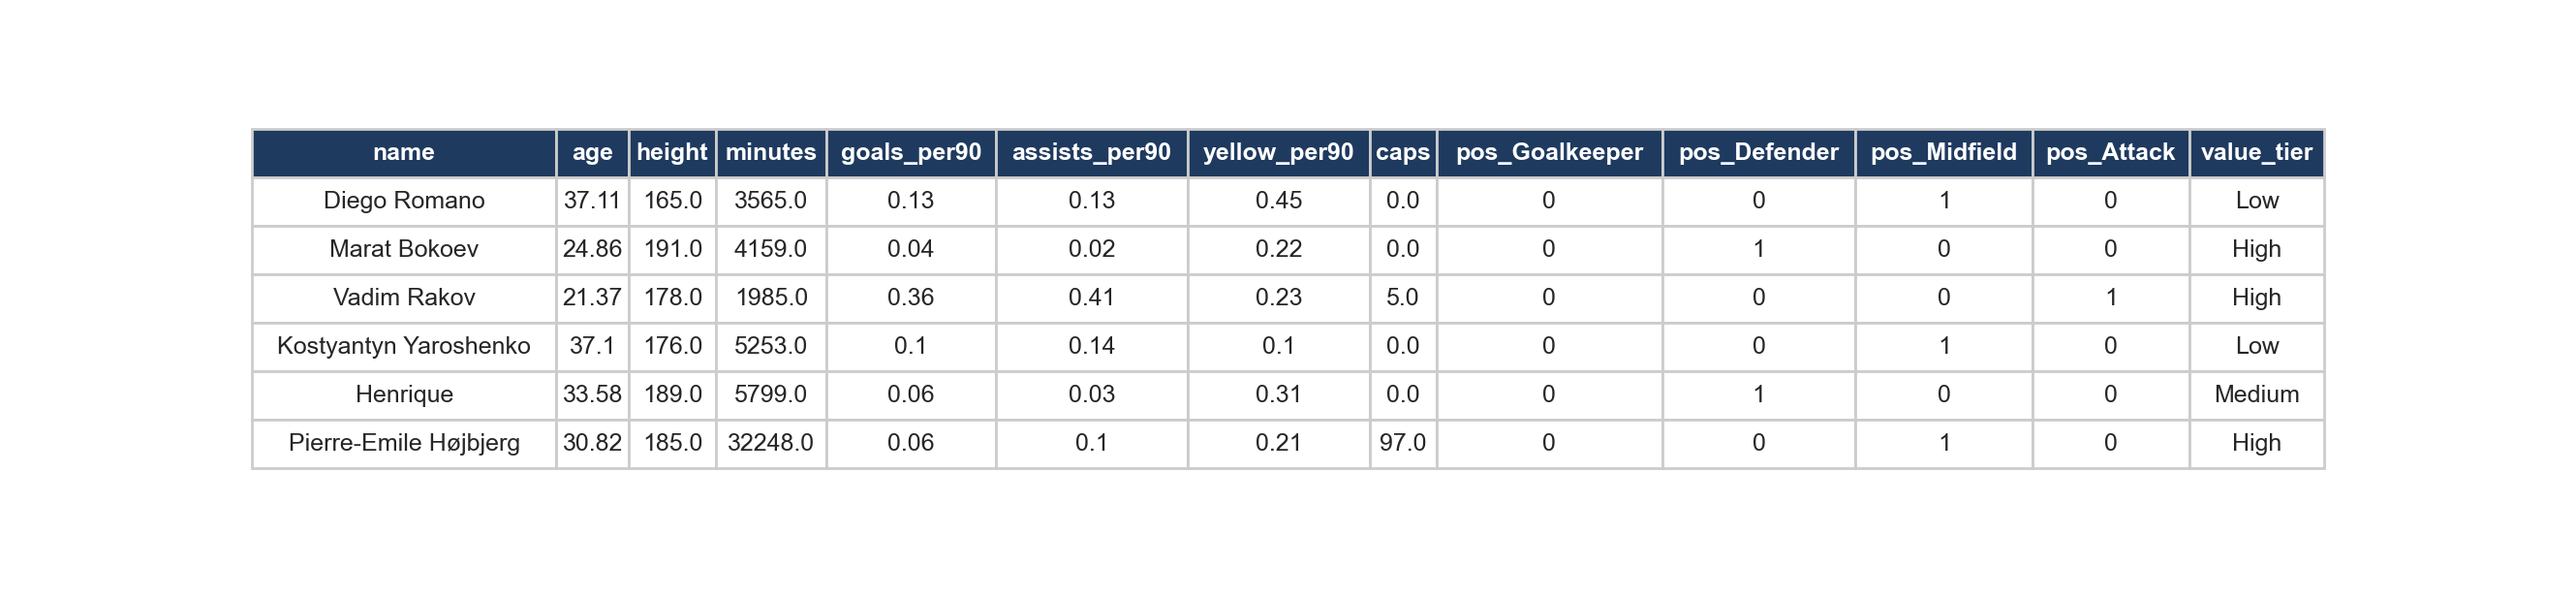

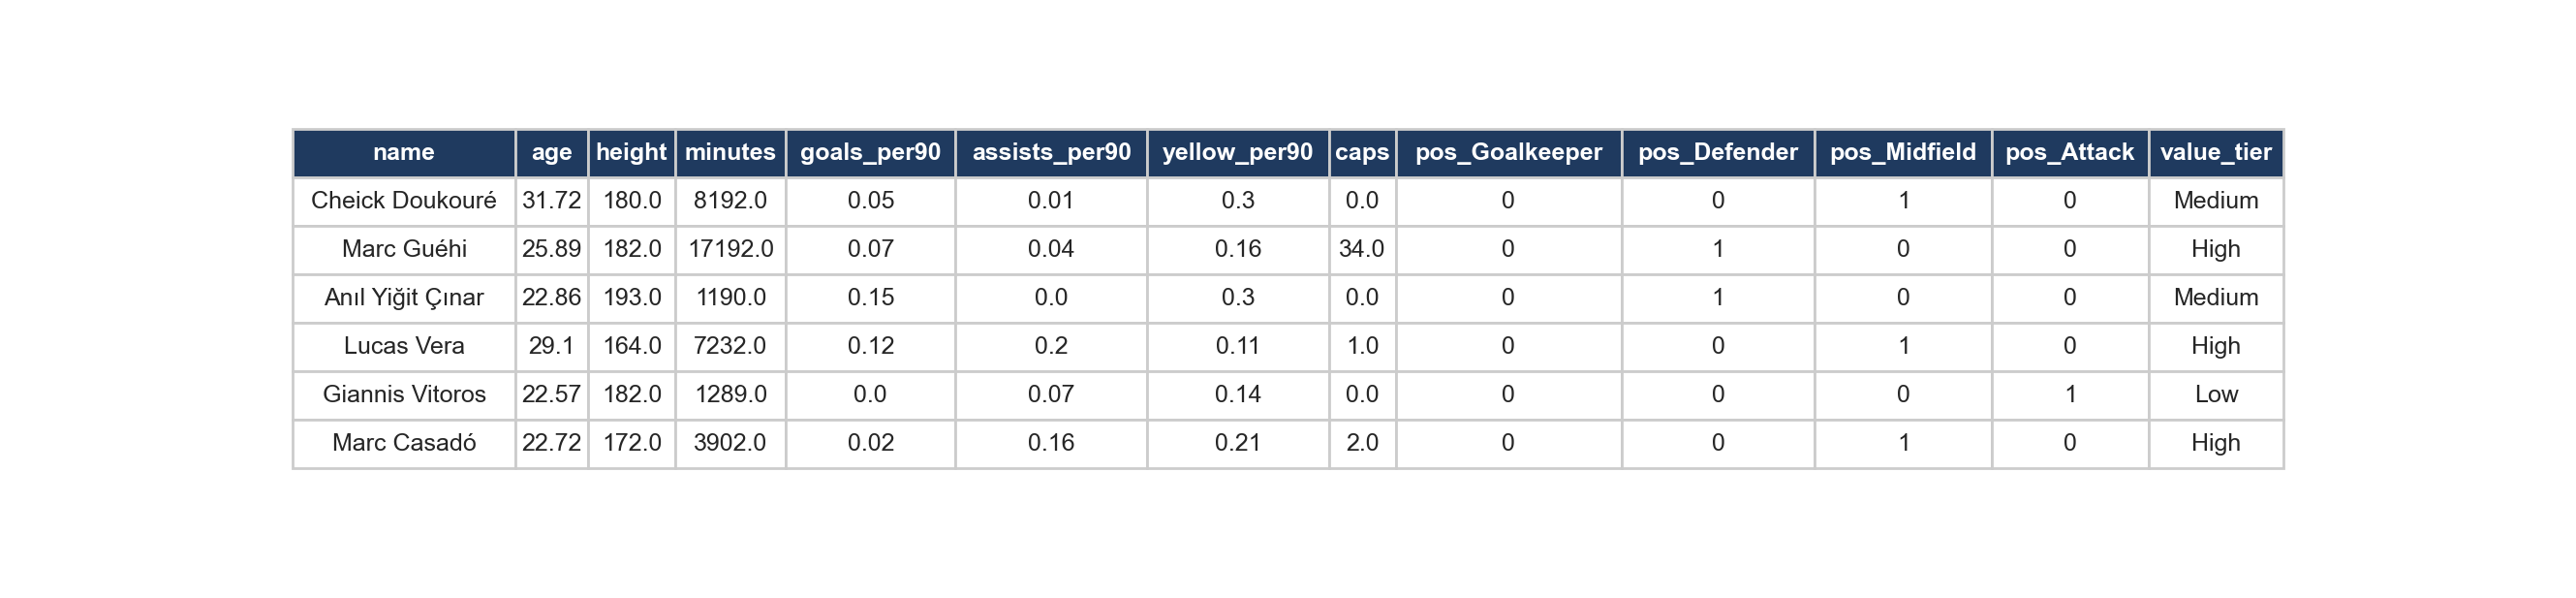

In [20]:
REG_X = ["age", "height", "minutes_log", "goals_per90", "assists_per90", "yellow_per90", "caps_log",
         "pos_Defender", "pos_Midfield", "pos_Attack"]
ADA_X = ["age", "height", "minutes", "goals_per90", "assists_per90", "yellow_per90", "caps",
         "pos_Goalkeeper", "pos_Defender", "pos_Midfield", "pos_Attack"]

reg_cols = ["name"] + REG_X + ["value_log", "is_high"]
ada_cols = ["name"] + ADA_X + ["value_tier"]
train[reg_cols].to_csv(SAMPLES / "reg_train.csv", index=False)
test[reg_cols].to_csv(SAMPLES / "reg_test.csv", index=False)
train[ada_cols].to_csv(SAMPLES / "ada_train.csv", index=False)
test[ada_cols].to_csv(SAMPLES / "ada_test.csv", index=False)

table_image(sample[reg_cols], IMG / "reg_sample.png", n=8)
table_image(train[reg_cols], IMG / "reg_train.png")
table_image(test[reg_cols], IMG / "reg_test.png")
table_image(sample[ada_cols], IMG / "ada_sample.png", n=8)
table_image(train[ada_cols], IMG / "ada_train.png")
table_image(test[ada_cols], IMG / "ada_test.png")

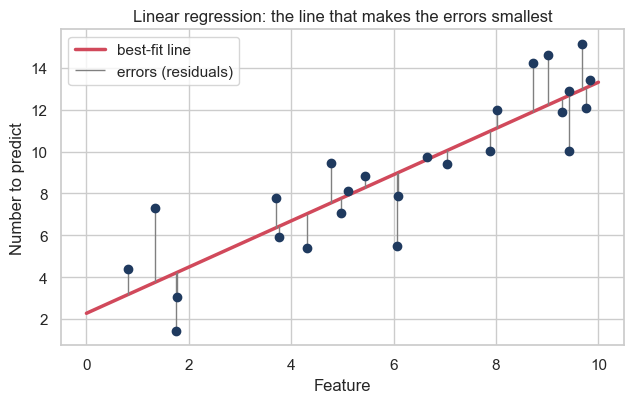

In [21]:
rng = np.random.default_rng(4)
x = rng.uniform(0, 10, 25)
y = 2 + 1.2 * x + rng.normal(0, 1.8, 25)
b, a = np.polyfit(x, y, 1)

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.scatter(x, y, color="#1f3a5f", zorder=3)
xs = np.array([0, 10])
ax.plot(xs, a + b * xs, color="#d1495b", lw=2.5, label="best-fit line")
ax.vlines(x, y, a + b * x, color="gray", lw=1, label="errors (residuals)")
ax.set_xlabel("Feature")
ax.set_ylabel("Number to predict")
ax.set_title("Linear regression: the line that makes the errors smallest")
ax.legend()
plt.tight_layout()
fig.savefig(IMG / "reg_ov_01_linear.png", dpi=200, bbox_inches="tight")
plt.show()

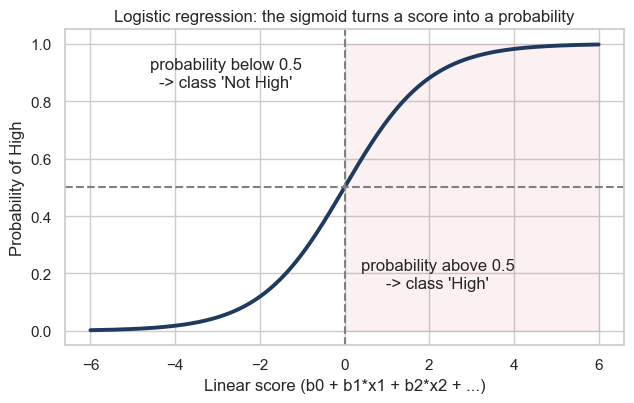

In [22]:
z = np.linspace(-6, 6, 300)
p = 1 / (1 + np.exp(-z))

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(z, p, color="#1f3a5f", lw=2.8)
ax.axhline(0.5, color="gray", ls="--")
ax.axvline(0, color="gray", ls="--")
ax.fill_between(z, 0, 1, where=z > 0, color="#d1495b", alpha=0.08)
ax.text(2.2, 0.15, "probability above 0.5\n-> class 'High'", ha="center")
ax.text(-2.8, 0.85, "probability below 0.5\n-> class 'Not High'", ha="center")
ax.set_xlabel("Linear score (b0 + b1*x1 + b2*x2 + ...)")
ax.set_ylabel("Probability of High")
ax.set_title("Logistic regression: the sigmoid turns a score into a probability")
plt.tight_layout()
fig.savefig(IMG / "reg_ov_02_sigmoid.png", dpi=200, bbox_inches="tight")
plt.show()

In [23]:
Xtr, Xte = train[REG_X], test[REG_X]
ytr, yte = train.value_log, test.value_log

lin = LinearRegression().fit(Xtr, ytr)
pred = lin.predict(Xte)

cv_r2 = cross_val_score(LinearRegression(), Xtr, ytr, cv=5, scoring="r2")
rmse = mean_squared_error(yte, pred) ** 0.5
mae = mean_absolute_error(yte, pred)
r2 = r2_score(yte, pred)

print("5-fold CV R2 on training data:", cv_r2.round(3), " mean:", cv_r2.mean().round(3))
print(f"TEST  RMSE: {rmse:.3f}   MAE: {mae:.3f}   R2: {r2:.3f}")
print(f"typical miss is a factor of about {np.exp(mae):.2f}x in euros (from MAE)")

5-fold CV R2 on training data: [0.619 0.612 0.606 0.591 0.589]  mean: 0.603
TEST  RMSE: 1.063   MAE: 0.862   R2: 0.581
typical miss is a factor of about 2.37x in euros (from MAE)


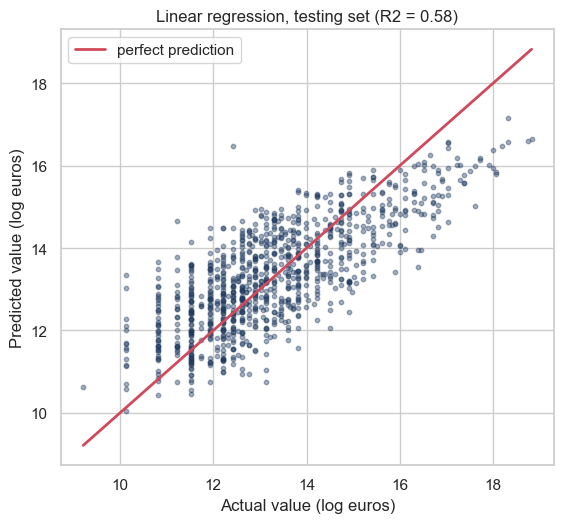

In [24]:
fig, ax = plt.subplots(figsize=(5.8, 5.4))
ax.scatter(yte, pred, s=10, alpha=0.4, color="#1f3a5f")
lims = [min(yte.min(), pred.min()), max(yte.max(), pred.max())]
ax.plot(lims, lims, color="#d1495b", lw=2, label="perfect prediction")
ax.set_xlabel("Actual value (log euros)")
ax.set_ylabel("Predicted value (log euros)")
ax.set_title(f"Linear regression, testing set (R2 = {r2:.2f})")
ax.legend()
plt.tight_layout()
fig.savefig(IMG / "reg_01_pred_vs_actual.png", dpi=200, bbox_inches="tight")
plt.show()

In [25]:
coef = pd.DataFrame({"feature": REG_X, "coefficient": lin.coef_})
coef["effect_on_value_pct"] = (np.exp(coef.coefficient) - 1) * 100
print("intercept:", round(lin.intercept_, 3))
print(coef.round(3).to_string(index=False))

intercept: 13.07
      feature  coefficient  effect_on_value_pct
          age       -0.217              -19.538
       height        0.010                0.993
  minutes_log        0.568               76.501
  goals_per90        1.538              365.343
assists_per90        1.515              355.146
 yellow_per90       -0.048               -4.718
     caps_log        0.338               40.201
 pos_Defender       -0.341              -28.864
 pos_Midfield       -0.367              -30.698
   pos_Attack       -0.638              -47.150


      C  cv_accuracy
  0.001       0.7895
  0.010       0.8352
  0.100       0.8415
  1.000       0.8418
 10.000       0.8427
100.000       0.8430
chosen C: 100


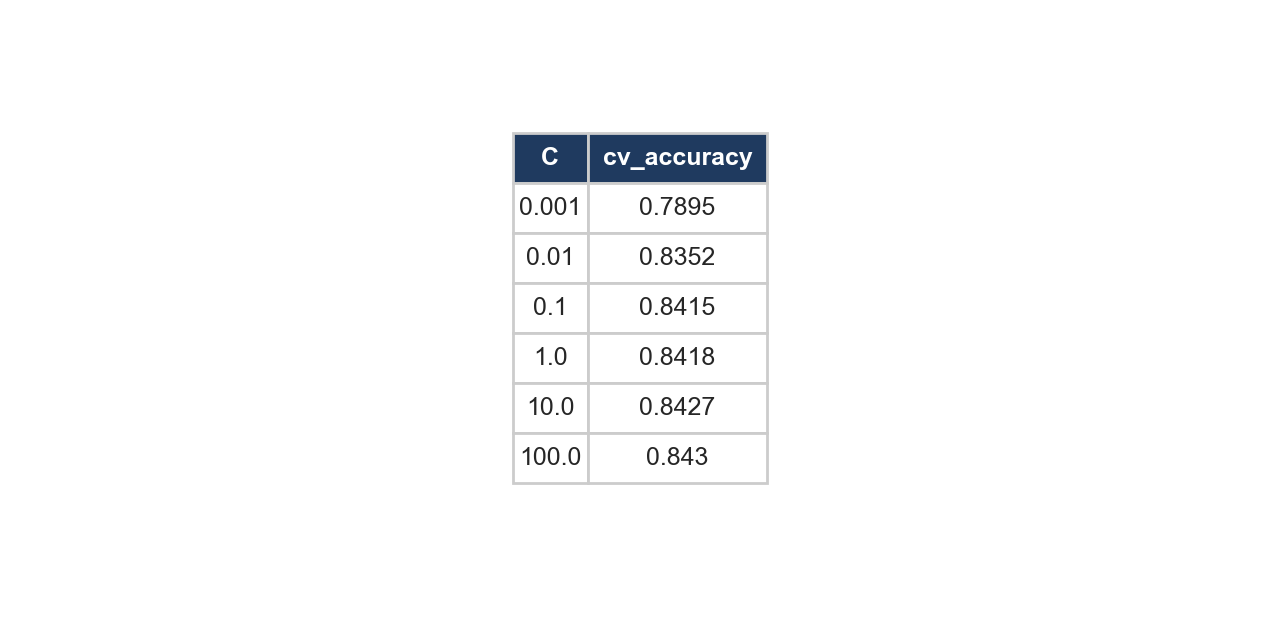

In [26]:
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
grid = GridSearchCV(pipe, {"logisticregression__C": [0.001, 0.01, 0.1, 1, 10, 100]}, cv=5, scoring="accuracy")
grid.fit(train[REG_X], train.is_high)

cv = pd.DataFrame({"C": [0.001, 0.01, 0.1, 1, 10, 100], "cv_accuracy": grid.cv_results_["mean_test_score"]})
print(cv.round(4).to_string(index=False))
print("chosen C:", grid.best_params_["logisticregression__C"])

table_image(cv, IMG / "reg_cv_table.png", n=6, decimals=4)

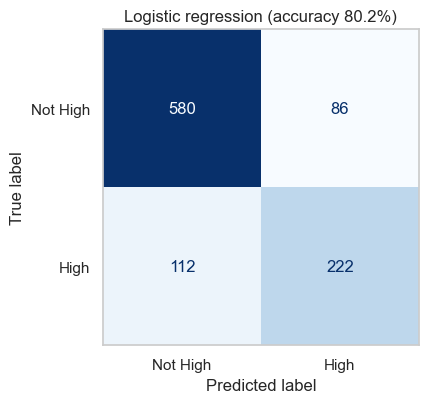

[[580  86]
 [112 222]]
accuracy 0.802   always guessing 'Not High': 0.666
      feature  odds_ratio_per_1_SD
  minutes_log                3.753
     caps_log                1.979
  goals_per90                1.503
assists_per90                1.423
       height                1.169
 yellow_per90                1.055
 pos_Defender                0.684
 pos_Midfield                0.667
   pos_Attack                0.559
          age                0.131


In [27]:
logit = grid.best_estimator_
lpred = logit.predict(test[REG_X])
logit_acc = accuracy_score(test.is_high, lpred)
base = 1 - test.is_high.mean()

fig, ax = plt.subplots(figsize=(4.6, 4.2))
ConfusionMatrixDisplay.from_predictions(test.is_high, lpred, display_labels=["Not High", "High"], ax=ax,
                                        cmap="Blues", colorbar=False)
ax.set_title(f"Logistic regression (accuracy {logit_acc:.1%})")
ax.grid(False)
plt.tight_layout()
fig.savefig(IMG / "reg_02_logit_confusion.png", dpi=200, bbox_inches="tight")
plt.show()

print(confusion_matrix(test.is_high, lpred))
print(f"accuracy {logit_acc:.3f}   always guessing 'Not High': {base:.3f}")

odds = pd.DataFrame({"feature": REG_X, "odds_ratio_per_1_SD": np.exp(logit[-1].coef_[0])})
print(odds.round(3).sort_values("odds_ratio_per_1_SD", ascending=False).to_string(index=False))

              model  test_accuracy
Logistic regression          0.802
        Gaussian NB          0.769
     Multinomial NB          0.711
  Always 'Not High'          0.666


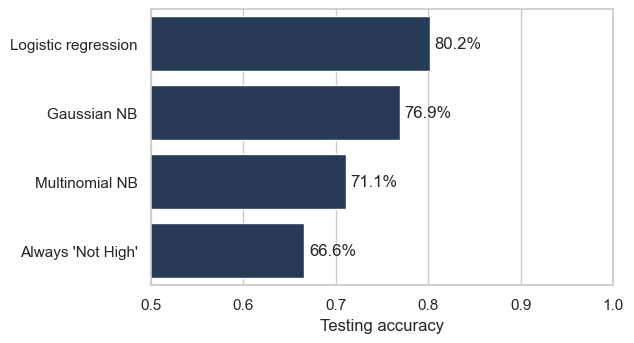

In [28]:
gnb = GaussianNB().fit(train[REG_X], train.is_high)
mm = MinMaxScaler().fit(train[REG_X])
mnb = MultinomialNB().fit(mm.transform(train[REG_X]), train.is_high)

cmp = pd.DataFrame({
    "model": ["Logistic regression", "Gaussian NB", "Multinomial NB", "Always 'Not High'"],
    "test_accuracy": [logit_acc,
                      accuracy_score(test.is_high, gnb.predict(test[REG_X])),
                      accuracy_score(test.is_high, mnb.predict(np.clip(mm.transform(test[REG_X]), 0, 1))),
                      base]})
print(cmp.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(6.5, 3.6))
sns.barplot(data=cmp, y="model", x="test_accuracy", color="#1f3a5f", ax=ax)
ax.set_xlim(0.5, 1); ax.set_xlabel("Testing accuracy"); ax.set_ylabel("")
for i, v in enumerate(cmp.test_accuracy):
    ax.text(v + 0.005, i, f"{v:.1%}", va="center")
plt.tight_layout()
fig.savefig(IMG / "reg_03_vs_naive_bayes.png", dpi=200, bbox_inches="tight")
plt.show()

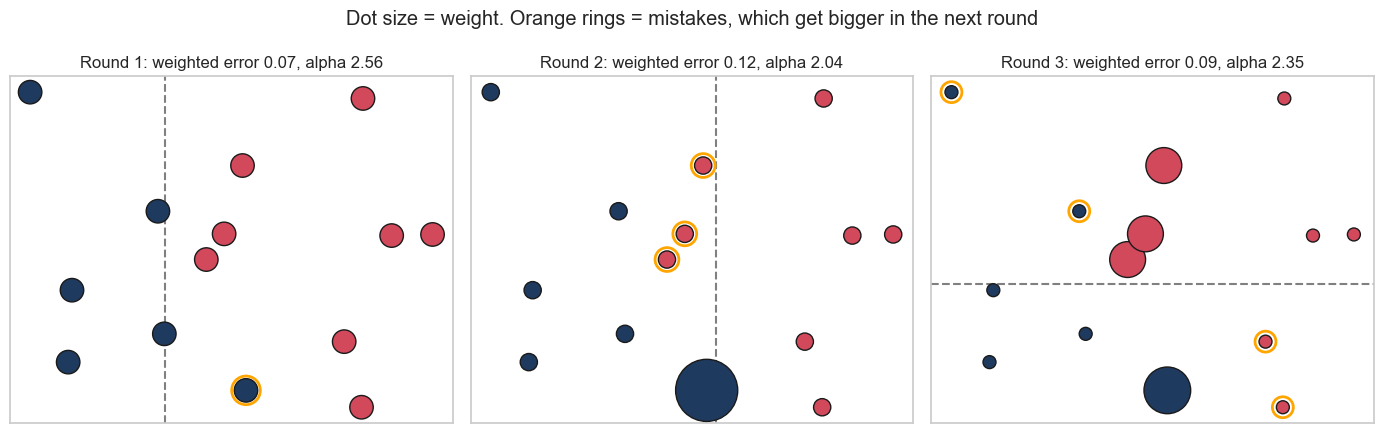

In [29]:
rng = np.random.default_rng(3)
X = rng.uniform(0, 10, (14, 2))
y = np.where(X[:, 0] + X[:, 1] + rng.normal(0, 2, 14) > 10, 1, -1)
w = np.ones(14) / 14

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for r, ax in enumerate(axes):
    best = None
    for f in (0, 1):
        for t in np.linspace(0.5, 9.5, 19):
            for s in (1, -1):
                pr = np.where(X[:, f] > t, s, -s)
                err = w[pr != y].sum()
                if best is None or err < best[0]:
                    best = (err, f, t, s)
    err, f, t, s = best
    pr = np.where(X[:, f] > t, s, -s)
    alpha = np.log((1 - err) / err)
    wrong = pr != y
    ax.scatter(X[:, 0], X[:, 1], s=w * 4000, c=np.where(y == 1, "#d1495b", "#1f3a5f"), edgecolor="k", zorder=3)
    ax.scatter(X[wrong, 0], X[wrong, 1], s=w[wrong] * 4000 + 140, facecolor="none", edgecolor="orange", lw=2, zorder=4)
    (ax.axvline if f == 0 else ax.axhline)(t, color="gray", ls="--")
    ax.set_title(f"Round {r + 1}: weighted error {err:.2f}, alpha {alpha:.2f}")
    ax.set_xticks([]); ax.set_yticks([])
    w = w * np.exp(alpha * wrong)
    w = w / w.sum()
fig.suptitle("Dot size = weight. Orange rings = mistakes, which get bigger in the next round")
plt.tight_layout()
fig.savefig(IMG / "ada_ov_01_reweighting.png", dpi=200, bbox_inches="tight")
plt.show()

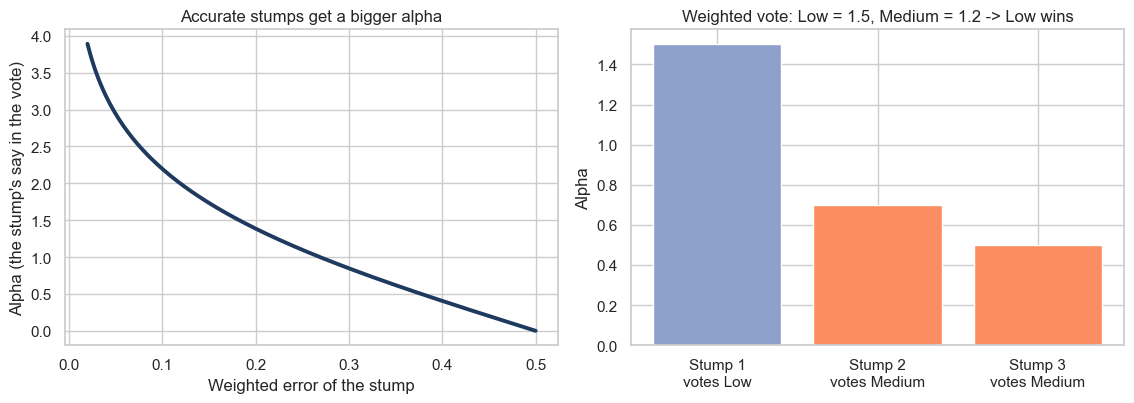

In [30]:
e = np.linspace(0.02, 0.5, 200)
alpha = np.log((1 - e) / e)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
axes[0].plot(e, alpha, color="#1f3a5f", lw=2.8)
axes[0].set_xlabel("Weighted error of the stump")
axes[0].set_ylabel("Alpha (the stump's say in the vote)")
axes[0].set_title("Accurate stumps get a bigger alpha")

alphas = [1.5, 0.7, 0.5]
votes = ["Low", "Medium", "Medium"]
colors = {"Low": "#8da0cb", "Medium": "#fc8d62"}
axes[1].bar([f"Stump {i + 1}\nvotes {v}" for i, v in enumerate(votes)], alphas, color=[colors[v] for v in votes])
tot = {k: sum(a for a, v in zip(alphas, votes) if v == k) for k in colors}
axes[1].set_ylabel("Alpha")
axes[1].set_title(f"Weighted vote: Low = {tot['Low']:.1f}, Medium = {tot['Medium']:.1f} -> Low wins")
plt.tight_layout()
fig.savefig(IMG / "ada_ov_02_alpha_vote.png", dpi=200, bbox_inches="tight")
plt.show()

best learning rate: 1.0   best number of rounds: 299   CV accuracy: 0.645
lr 0.1: best CV accuracy 0.632 at 300 rounds
lr 0.5: best CV accuracy 0.642 at 192 rounds
lr 1.0: best CV accuracy 0.645 at 299 rounds


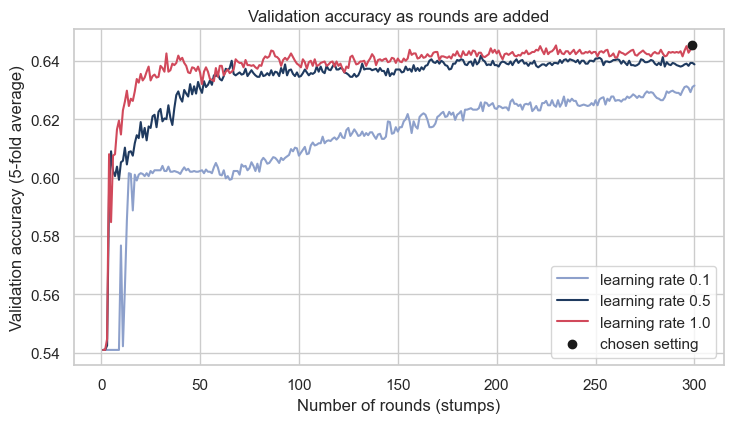

In [31]:
Xa, ya = train[ADA_X], train.value_tier
Xa_te, ya_te = test[ADA_X], test.value_tier

stump = DecisionTreeClassifier(max_depth=1)
LRS, MAX_N = [0.1, 0.5, 1.0], 300
skf = StratifiedKFold(5, shuffle=True, random_state=42)

curves = {}
for lr in LRS:
    scores = []
    for tr_i, va_i in skf.split(Xa, ya):
        m = AdaBoostClassifier(estimator=stump, n_estimators=MAX_N, learning_rate=lr, random_state=42)
        m.fit(Xa.iloc[tr_i], ya.iloc[tr_i])
        scores.append(list(m.staged_score(Xa.iloc[va_i], ya.iloc[va_i])))
    curves[lr] = np.mean(scores, axis=0)

best_lr = max(curves, key=lambda k: curves[k].max())
best_n = int(curves[best_lr].argmax()) + 1
print(f"best learning rate: {best_lr}   best number of rounds: {best_n}   CV accuracy: {curves[best_lr].max():.3f}")
for lr in LRS:
    print(f"lr {lr}: best CV accuracy {curves[lr].max():.3f} at {int(curves[lr].argmax()) + 1} rounds")

fig, ax = plt.subplots(figsize=(7.5, 4.4))
for lr, c in zip(LRS, ["#8da0cb", "#1f3a5f", "#d1495b"]):
    ax.plot(range(1, MAX_N + 1), curves[lr], color=c, label=f"learning rate {lr}")
ax.scatter([best_n], [curves[best_lr].max()], color="k", zorder=5, label="chosen setting")
ax.set_xlabel("Number of rounds (stumps)")
ax.set_ylabel("Validation accuracy (5-fold average)")
ax.set_title("Validation accuracy as rounds are added")
ax.legend()
plt.tight_layout()
fig.savefig(IMG / "ada_01_validation_curve.png", dpi=200, bbox_inches="tight")
plt.show()

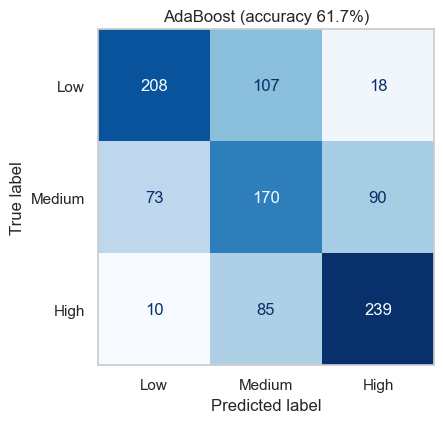

[[208 107  18]
 [ 73 170  90]
 [ 10  85 239]]
AdaBoost test accuracy: 0.617


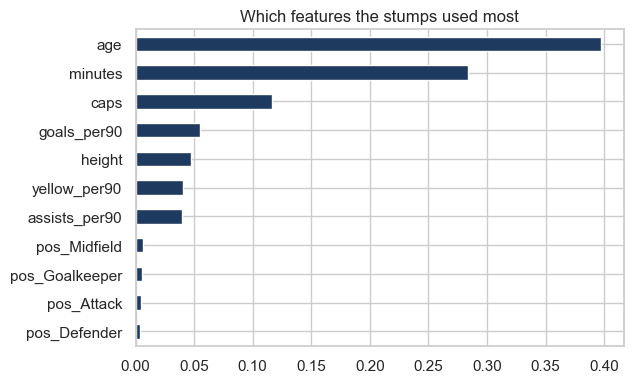

age            0.397
minutes        0.284
caps           0.116
goals_per90    0.055
dtype: float64


In [32]:
ada = AdaBoostClassifier(estimator=stump, n_estimators=best_n, learning_rate=best_lr, random_state=42).fit(Xa, ya)
apred = ada.predict(Xa_te)
ada_acc = accuracy_score(ya_te, apred)
TIERS = ["Low", "Medium", "High"]

fig, ax = plt.subplots(figsize=(4.8, 4.4))
ConfusionMatrixDisplay.from_predictions(ya_te, apred, labels=TIERS, ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"AdaBoost (accuracy {ada_acc:.1%})")
ax.grid(False)
plt.tight_layout()
fig.savefig(IMG / "ada_02_confusion.png", dpi=200, bbox_inches="tight")
plt.show()

print(confusion_matrix(ya_te, apred, labels=TIERS))
print(f"AdaBoost test accuracy: {ada_acc:.3f}")

imp = pd.Series(ada.feature_importances_, index=ADA_X).sort_values()
fig, ax = plt.subplots(figsize=(6.5, 4))
imp[imp > 0].plot.barh(ax=ax, color="#1f3a5f")
ax.set_title("Which features the stumps used most")
plt.tight_layout()
fig.savefig(IMG / "ada_03_importances.png", dpi=200, bbox_inches="tight")
plt.show()
print(imp.sort_values(ascending=False).head(4).round(3))

                 model  test_accuracy
             One stump          0.529
Decision tree (Tree 2)          0.605
              AdaBoost          0.617
AdaBoost minus decision tree: +1.2 points


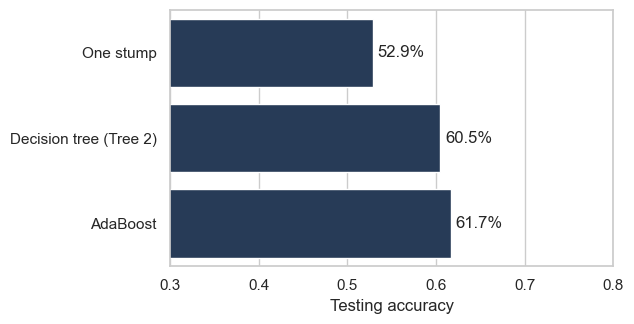

In [33]:
tree = DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=42)
tree.fit(train[ADA_X], ya)
tree_acc = accuracy_score(ya_te, tree.predict(Xa_te))

one_stump = DecisionTreeClassifier(max_depth=1, random_state=42).fit(Xa, ya)
stump_acc = accuracy_score(ya_te, one_stump.predict(Xa_te))

cmp2 = pd.DataFrame({"model": ["One stump", "Decision tree (Tree 2)", "AdaBoost"],
                     "test_accuracy": [stump_acc, tree_acc, ada_acc]})
print(cmp2.round(3).to_string(index=False))
print(f"AdaBoost minus decision tree: {100 * (ada_acc - tree_acc):+.1f} points")

fig, ax = plt.subplots(figsize=(6.5, 3.4))
sns.barplot(data=cmp2, y="model", x="test_accuracy", color="#1f3a5f", ax=ax)
ax.set_xlim(0.3, 0.8); ax.set_xlabel("Testing accuracy"); ax.set_ylabel("")
for i, v in enumerate(cmp2.test_accuracy):
    ax.text(v + 0.005, i, f"{v:.1%}", va="center")
plt.tight_layout()
fig.savefig(IMG / "ada_04_vs_tree.png", dpi=200, bbox_inches="tight")
plt.show()

In [34]:
needed = ["reg_sample", "reg_train", "reg_test", "reg_cv_table", "reg_ov_01_linear", "reg_ov_02_sigmoid",
          "reg_01_pred_vs_actual", "reg_02_logit_confusion", "reg_03_vs_naive_bayes",
          "ada_sample", "ada_train", "ada_test", "ada_ov_01_reweighting", "ada_ov_02_alpha_vote",
          "ada_01_validation_curve", "ada_02_confusion", "ada_03_importances", "ada_04_vs_tree"]
for n in needed:
    print("ok     " if (IMG / f"{n}.png").exists() else "MISSING", f"images/{n}.png")
for n in ["reg_train", "reg_test", "ada_train", "ada_test"]:
    print("ok     " if (SAMPLES / f"{n}.csv").exists() else "MISSING", f"data/samples/{n}.csv")

ok      images/reg_sample.png
ok      images/reg_train.png
ok      images/reg_test.png
ok      images/reg_cv_table.png
ok      images/reg_ov_01_linear.png
ok      images/reg_ov_02_sigmoid.png
ok      images/reg_01_pred_vs_actual.png
ok      images/reg_02_logit_confusion.png
ok      images/reg_03_vs_naive_bayes.png
ok      images/ada_sample.png
ok      images/ada_train.png
ok      images/ada_test.png
ok      images/ada_ov_01_reweighting.png
ok      images/ada_ov_02_alpha_vote.png
ok      images/ada_01_validation_curve.png
ok      images/ada_02_confusion.png
ok      images/ada_03_importances.png
ok      images/ada_04_vs_tree.png
ok      data/samples/reg_train.csv
ok      data/samples/reg_test.csv
ok      data/samples/ada_train.csv
ok      data/samples/ada_test.csv
